# Sentiment Analysis
- A área de processamento de Linguagem Natural é uma área essencial do Aprendizado de máquina.
- Essa técnica permite que os computadores possam entender e processar linguagem humana.

1) > Nesse estudo irei mostrar como essa ténica permite que criemos aplicações avançadas, nos permitindo ir além e desenvolver soluções que apoiem decisões de negócio de forma robusta e proativa.
2) > Iremos treinar uma rede neural capaz de entender o sentimento predominante dos usuários e nos permitir monitorar cada mudança, permitindo-nos tomar decisões proativas em relação aos usuários.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import random
import os

import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Importações para Tokenização mais Robusta
from tokenizers import Tokenizer
from tokenizers.models import WordPiece
from tokenizers.trainers import WordPieceTrainer
from tokenizers.pre_tokenizers import Whitespace

# Importações para criação da Rede Neural (Tensorflow)
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.metrics import AUC
import tensorflow_datasets as tfds

print(tf.__version__)

2.21.0


## Técnica 2: LSTMs + WordPiece
- Essa técnica consiste em...

In [3]:
train_file_path = Path("processed_data") / "clean_tweets.parquet"
train_data = pd.read_parquet(train_file_path,
                        engine="pyarrow")
train_data.head(3)

,text,sentiments
0,only if you know you should be do something el...,1
1,I nver get thru any radio station ever but I m...,0
2,look like hour to sandusky oh hmmmmm .... husb...,1


In [4]:
data = train_data.copy()
data.tail()

,text,sentiments
316288,skate online saddd and lonelyy,0
316289,tweep good morning,1
316290,you never get back to I on the previous painti...,0
316291,sunbathe in the garden but it get a little too...,1
316292,google wave trend replace this conan person go...,1


In [5]:
unique, counts = np.unique(data["sentiments"], return_counts=True)
print(f"Valores únicos -> {unique[0]}, {unique[1]}  - Contagem -> {counts[0]}, {counts[1]}")

Valores únicos -> 0, 1  - Contagem -> 158037, 158256


In [6]:
sample_text = train_data.loc[0, "text"]
print(sample_text)

only if you know you should be do something else ...


In [7]:
sample_X = train_data.loc[:, "text"]
sample_y = train_data.loc[:, "sentiments"]

In [8]:
for _ in range(10):
    print(sample_X[random.randint(0, len(sample_X) - 1)])

wish rob big be have a huge marathon right now I miss that show
switch back to firefox today ....... safari crash way too much
open jrocket tomorrow but off at night mmm .. I m think star trek movie buddy
heyy I think you re really awesome come down to singapore someday your fan base here be really big
aww no which one
my twitter be mess up
I have a new home help she s lovely crucially she be very good at her job it s a shame they work to a rota system
you need to join in with twitprentice
morning all blue sky and sunny here I m up with the girl but feel like c
yeahlol or when they do they do not come to myside ivebeen wait for jb forage andthere coman in dec but I m gunna be inamerica


In [9]:
# 1. Inicializa o modelo básico WordPiece com um token para palavras desconhecidas [UNK]
tokenizer = Tokenizer(WordPiece(unk_token="[UNK]"))

# 2. Configura o pré-tokenizador para separar por espaços em branco e pontuações
tokenizer.pre_tokenizer = Whitespace()

# 3. Configura o treinador definindo os tokens especiais e o tamanho do vocabulário desejado (ex: 65536)
trainer = WordPieceTrainer(
    vocab_size=2**16, 
    special_tokens=["[PAD]", "[UNK]", "[START]", "[END]"]
)

# 4. Treina o tokenizador diretamente a partir dos dados textuais (X)
# Se X for uma Series do Pandas ou Array NumPy de tweets:
tweets_corpus = sample_X.tolist() if hasattr(sample_X, 'tolist') else list(sample_X)
tokenizer.train_from_iterator(tweets_corpus, trainer)

print(f"Vocabulário treinado com sucesso! Tamanho real: {tokenizer.get_vocab_size()}")

Vocabulário treinado com sucesso! Tamanho real: 65536


In [10]:
ids = tokenizer.encode("I am very happy")
ids

Encoding(num_tokens=4, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])

In [11]:
ids.tokens

['I', 'am', 'very', 'happy']

In [12]:
ids.ids

[7, 552, 398, 391]

In [13]:
text = tokenizer.decode(ids.ids)
text

'I am very happy'

In [14]:
input_data = [tokenizer.encode(sentence) for sentence in sample_X]
input_data[0]

Encoding(num_tokens=11, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])

In [15]:
for _ in range(10):
    print(input_data[random.randint(0, len(input_data) - 1)])

Encoding(num_tokens=8, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Encoding(num_tokens=4, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Encoding(num_tokens=6, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Encoding(num_tokens=23, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Encoding(num_tokens=5, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Encoding(num_tokens=20, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Encoding(num_tokens=24, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Encoding(num_tokens=21, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Encoding(num_tokens=18, attributes=[ids, type_ids, t

In [16]:
input_data[0].ids

[386, 287, 87, 229, 87, 411, 68, 115, 588, 1055, 98]

In [17]:
input_data_ids = [enc.ids for enc in input_data]

In [18]:
max_len = max([len(sentence) for sentence in input_data])
max_len

49

In [19]:
data_inputs = tf.keras.preprocessing.sequence.pad_sequences(
    input_data_ids,
    value=0,
    padding="post",
    maxlen=max_len
)

In [20]:
for _ in range(5):
    print(data_inputs[random.randint(0, len(input_data) - 1)])

[11069  3763   463    27   111   105  2811 57550    54   463    27   111
   105  9000  1769   196   205   140   178  1769     7   186  1769     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0]
[ 560  402  732  231 1717   87    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0]
[  95  172  119  147  196   92 3279  734    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0]
[ 5611   751    99 44290   440  6594  1352   398   154   888 24662     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0

In [21]:
print(len(data_inputs), len(sample_y))

316293 316293


In [22]:
train_inputs, test_inputs, train_labels, test_labels = train_test_split(
                                        data_inputs,
                                        sample_y,
                                        test_size=0.3,
                                        stratify=sample_y,
                                        random_state=42)
train_inputs

array([[   7,  115,  116, ...,    0,    0,    0],
       [ 300, 3544,  641, ...,    0,    0,    0],
       [6390,  115,   29, ...,    0,    0,    0],
       ...,
       [  72,   90, 3875, ...,    0,    0,    0],
       [7991,   99,   72, ...,    0,    0,    0],
       [ 809,  745,   95, ...,    0,    0,    0]],
      shape=(221405, 49), dtype=int32)

In [23]:
train_inputs.shape

(221405, 49)

In [24]:
train_labels.shape

(221405,)

In [25]:
class LSTMModel(tf.keras.Model):

    def __init__(self,
                 vocab_size,
                 embed_dim=128,
                 nb_filters=50,        # mantido p/ compatibilidade: vira o nº de unidades da LSTM
                 ffn_units=512,
                 nb_classes=2,
                 dropout_rate=0.1,
                 training=False,
                 lstm_units=None,      # opcional: sobrescreve nb_filters
                 bidirectional=True,
                 name="lstm"):
        super(LSTMModel, self).__init__(name=name)
        lstm_units = lstm_units or nb_filters

        # mask_zero=True faz a LSTM ignorar o padding (índice 0)
        self.embedding = layers.Embedding(vocab_size, embed_dim, mask_zero=True)

        lstm = layers.LSTM(lstm_units, return_sequences=True)
        self.lstm = layers.Bidirectional(lstm) if bidirectional else lstm

        
        self.dense_1 = layers.Dense(units=ffn_units, activation="relu")
        self.dropout = layers.Dropout(rate=dropout_rate)
        if nb_classes == 2:
            self.last_dense = layers.Dense(units=1, activation="sigmoid")
        else:
            self.last_dense = layers.Dense(units=nb_classes, activation="softmax")

    def call(self, inputs, training=False):
        mask = self.embedding.compute_mask(inputs)
        X = self.embedding(inputs)
        X = self.lstm(X, mask=mask, training=training)

        if mask is not None:
            neg = tf.constant(X.dtype.min, dtype=X.dtype)
            X = tf.where(mask[:, :, tf.newaxis], X, neg)
        
        X = tf.reduce_max(X, axis=1)
        has_tokens = tf.reduce_any(mask, axis=1, keepdims=True)
        X = tf.where(has_tokens, X, tf.zeros_like(X)) 

        X = self.dense_1(X)
        X = self.dropout(X, training=training)

        return self.last_dense(X)

In [26]:
vocab_size = tokenizer.get_vocab_size()
embed_dim = 200
nb_filters = 50
ffn_units = 128
nb_classes = len(set(train_labels))
batch_size = 64

dropout_rate = 0.30
nb_epochs = 5

In [27]:
# Instanciação da Classe
LSTM = LSTMModel(
    vocab_size=vocab_size,
    embed_dim=embed_dim,
    nb_filters=nb_filters,
    ffn_units=ffn_units,
    nb_classes=nb_classes,
    dropout_rate=dropout_rate
)

In [28]:
if nb_classes == 2:    
    LSTM.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy", AUC(name='auc')])
else:
    LSTM.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy", AUC(name='auc')])
    

In [29]:
folder_path = "checkpoints"
if not os.path.exists(folder_path):
    os.makedirs(folder_path, exist_ok=True)
checkpoint = folder_path
ckpt = tf.train.Checkpoint(LSTM=LSTM)
ckpt_manager = tf.train.CheckpointManager(ckpt, checkpoint, max_to_keep=5)
if ckpt_manager.latest_checkpoint:
    ckpt.restore(ckpt_manager.latest_checkpoint)
    print("Latest Checkpoint restored")
    

In [30]:
history = LSTM.fit(train_inputs, train_labels, 
                  batch_size=batch_size,
                  epochs=nb_epochs, verbose=1,
                  validation_split=0.2)

ckpt_manager.save()

Epoch 1/5
2768/2768 ━━━━━━━━━━━━━━━━━━━━ 898s 321ms/step - accuracy: 0.7850 - auc: 0.8664 - loss: 0.4562 - val_accuracy: 0.8047 - val_auc: 0.8866 - val_loss: 0.4234
Epoch 2/5
2768/2768 ━━━━━━━━━━━━━━━━━━━━ 853s 308ms/step - accuracy: 0.8404 - auc: 0.9202 - loss: 0.3589 - val_accuracy: 0.8034 - val_auc: 0.8839 - val_loss: 0.4377
Epoch 3/5
2768/2768 ━━━━━━━━━━━━━━━━━━━━ 693s 247ms/step - accuracy: 0.8824 - auc: 0.9536 - loss: 0.2755 - val_accuracy: 0.7931 - val_auc: 0.8698 - val_loss: 0.4855
Epoch 4/5
2768/2768 ━━━━━━━━━━━━━━━━━━━━ 743s 247ms/step - accuracy: 0.9146 - auc: 0.9749 - loss: 0.2025 - val_accuracy: 0.7834 - val_auc: 0.8515 - val_loss: 0.6425
Epoch 5/5
2768/2768 ━━━━━━━━━━━━━━━━━━━━ 819s 296ms/step - accuracy: 0.9362 - auc: 0.9857 - loss: 0.1523 - val_accuracy: 0.7769 - val_auc: 0.8408 - val_loss: 0.8037


'checkpoints\\ckpt-1'

In [31]:
results = LSTM.evaluate(test_inputs, test_labels, batch_size=batch_size)
print(results)

1483/1483 ━━━━━━━━━━━━━━━━━━━━ 31s 21ms/step - accuracy: 0.7787 - auc: 0.8440 - loss: 0.7865
[0.7864727973937988, 0.7787497043609619, 0.8439875841140747]


In [32]:
y_pred_test = LSTM.predict(test_inputs)

2966/2966 ━━━━━━━━━━━━━━━━━━━━ 37s 12ms/step


In [33]:
y_pred_test[:10]

array([[9.9977779e-01],
       [9.9996334e-01],
       [2.5884148e-02],
       [3.6653851e-03],
       [9.2875712e-02],
       [2.7260938e-01],
       [8.7904406e-01],
       [5.8797526e-01],
       [9.9994773e-01],
       [4.3804201e-04]], dtype=float32)

In [ ]:
y_pred_test = (y_pred_test > 0.5).astype(int)
y_pred_test[:10]

array([[1],
       [1],
       [0],
       ...,
       [0],
       [1],
       [1]], shape=(1066, 1))

# Visualização e persistência das métricas

In [35]:
matrix = confusion_matrix(test_labels, y_pred_test)
matrix

array([[38803,  8608],
       [12386, 35091]])

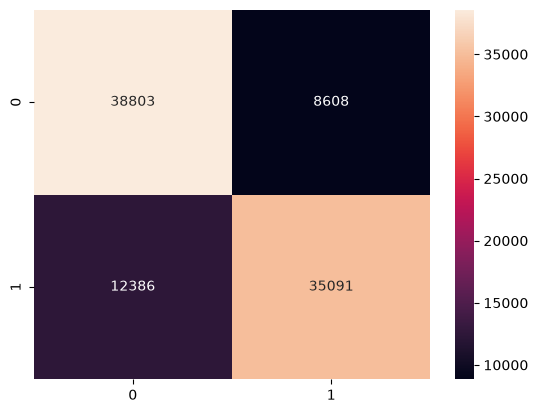

In [36]:
sns.heatmap(matrix, annot=True, robust=True, fmt=".0f")
plt.show()

In [37]:
accuracy = accuracy_score(test_labels, y_pred_test)
print(f"Accuracy: {(accuracy*100):.2f}%")

Accuracy: 77.87%


In [38]:
report = classification_report(test_labels, y_pred_test)
print(report)

              precision    recall  f1-score   support

           0       0.76      0.82      0.79     47411
           1       0.80      0.74      0.77     47477

    accuracy                           0.78     94888
   macro avg       0.78      0.78      0.78     94888
weighted avg       0.78      0.78      0.78     94888



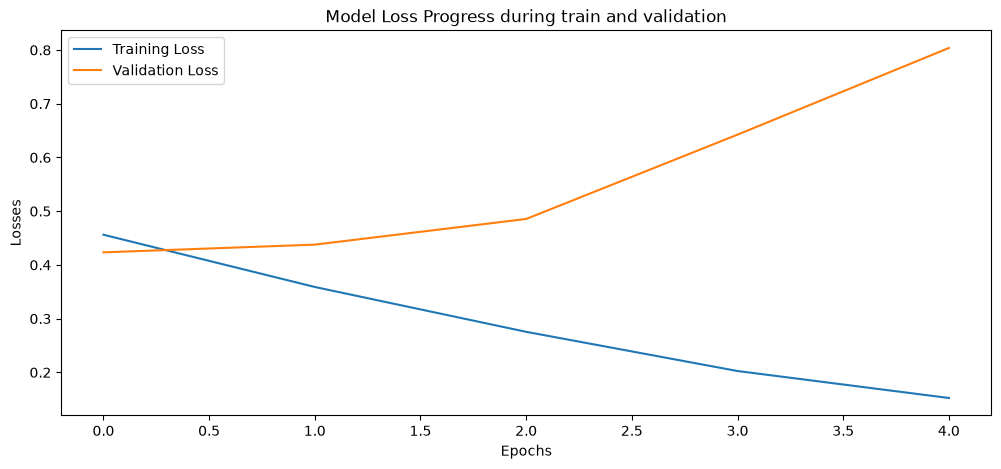

In [39]:
plt.figure(figsize=(12, 5))
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Model Loss Progress during train and validation")
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend(["Training Loss", "Validation Loss"])
plt.show()

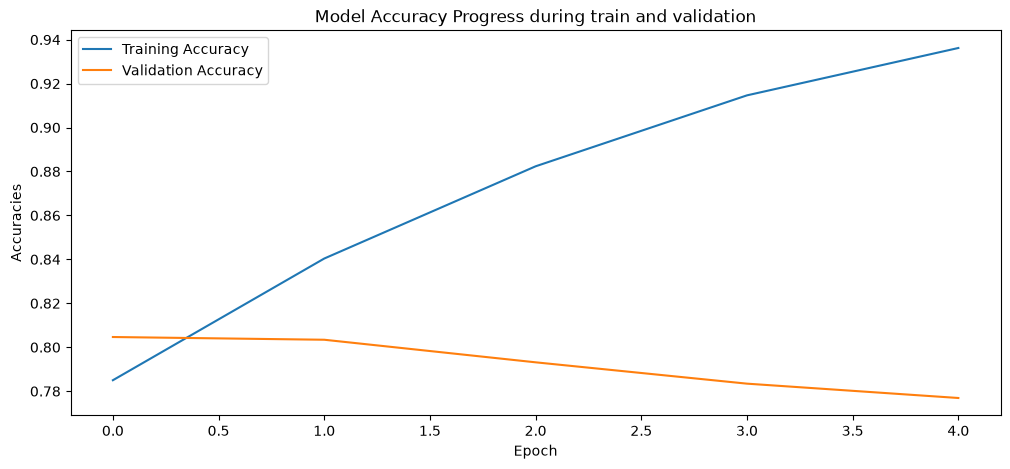

In [40]:
plt.figure(figsize=(12, 5))
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Model Accuracy Progress during train and validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracies")
plt.legend(["Training Accuracy", "Validation Accuracy"])
plt.show()

In [41]:
text = "you are so funny"
text = tokenizer.encode(text)
text

Encoding(num_tokens=4, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])

In [43]:
LSTM(np.array([text.ids]), training=False)

<tf.Tensor: shape=(1, 1), dtype=float32, numpy=array([[0.99997586]], dtype=float32)>

In [44]:
metrics_dir = Path("metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

with open(metrics_dir / "lstm_report.txt","w") as f:
    f.write(report)